In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/ABSS/biomet_data - biomet_data.csv")

In [ ]:
print(df.shape)
df.head()

(143, 1000)


,3.07E+02,2.97E+02,2.13E+02,1.95E+02,2.29E+02,2.50E+02,2.94E+02,1.71E+02,2.76E+02,2.89E+02,...,8.63E+01,8.21E+01,8.77E+01,8.06E+01,8.21E+01.1,8.03E+01.1,1.06E+02.10,1.44E+02.8,9.04E+01,1.34E+02.13
0,364.0,349.0,332.0,290.0,327.0,327.0,353.0,374.0,305.0,309.0,...,109.0,145.0,122.0,99.5,107.0,118.0,141.0,130.0,114.0,132.0
1,239.0,238.0,290.0,173.0,281.0,251.0,267.0,338.0,232.0,233.0,...,102.0,127.0,112.0,105.0,153.0,130.0,128.0,181.0,115.0,217.0
2,207.0,242.0,281.0,219.0,252.0,242.0,245.0,290.0,232.0,224.0,...,106.0,135.0,127.0,116.0,112.0,110.0,144.0,183.0,125.0,223.0
3,192.0,217.0,245.0,216.0,220.0,209.0,210.0,299.0,202.0,205.0,...,118.0,142.0,118.0,113.0,118.0,138.0,116.0,145.0,115.0,125.0
4,339.0,292.0,337.0,273.0,380.0,300.0,399.0,286.0,401.0,264.0,...,102.0,120.0,103.0,91.7,126.0,120.0,135.0,150.0,85.8,173.0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import euclidean
from sklearn.metrics.pairwise import cosine_similarity

print("Original Shape:", df.shape)

# Remove ALL column if present
if 'ALL' in df.columns:
    df = df.drop(columns=['ALL'])

print("After removing ALL column:", df.shape)

data = df.values

# If features are rows (144 rows)
if data.shape[0] == 144:
    data = data.T

print("Final Data Shape:", data.shape)

Original Shape: (143, 1000)
After removing ALL column: (143, 1000)
Final Data Shape: (143, 1000)


In [ ]:
# If current shape is (144,1000) or (143,1000)
# convert to (1000,144) or (1000,143)

if data.shape[0] < data.shape[1]:
    data = data.T

print("Working Shape:", data.shape)

NUM_USERS = 100
SAMPLES_PER_USER = 10

# Create enrollment templates
templates = []

for user in range(NUM_USERS):

    start = user * SAMPLES_PER_USER

    enrollment_samples = data[start:start+5]

    template = np.mean(enrollment_samples, axis=0)

    templates.append(template)

templates = np.array(templates)

print("Template Shape:", templates.shape)

Working Shape: (1000, 143)
Template Shape: (100, 143)


In [ ]:
eu_genuine = []
eu_imposter = []

cos_genuine = []
cos_imposter = []

for user in range(NUM_USERS):

    start = user * SAMPLES_PER_USER

    test_samples = data[start+5:start+10]

    for sample in test_samples:

        # Genuine score

        eu_genuine.append(
            euclidean(sample, templates[user])
        )

        cos_genuine.append(
            cosine_similarity(
                sample.reshape(1, -1),
                templates[user].reshape(1, -1)
            )[0][0]
        )

        # Imposter scores

        for other_user in range(NUM_USERS):

            if other_user == user:
                continue

            eu_imposter.append(
                euclidean(
                    sample,
                    templates[other_user]
                )
            )

            cos_imposter.append(
                cosine_similarity(
                    sample.reshape(1, -1),
                    templates[other_user].reshape(1, -1)
                )[0][0]
            )

eu_genuine = np.array(eu_genuine)
eu_imposter = np.array(eu_imposter)

cos_genuine = np.array(cos_genuine)
cos_imposter = np.array(cos_imposter)

print("Genuine Comparisons :", len(eu_genuine))
print("Imposter Comparisons:", len(eu_imposter))

Genuine Comparisons : 500
Imposter Comparisons: 49500


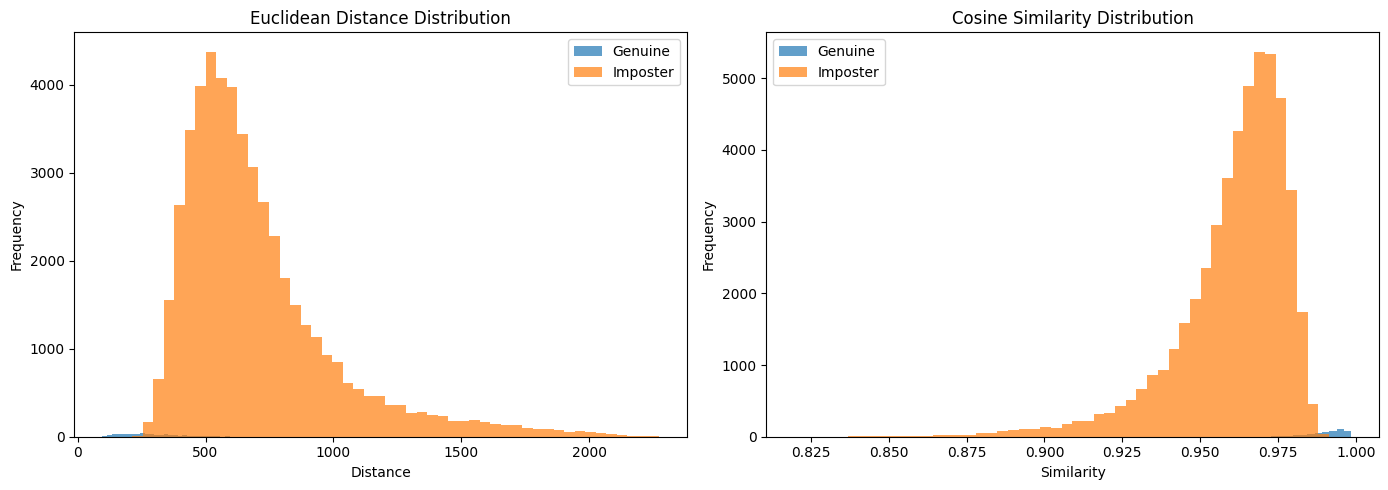

In [ ]:
plt.figure(figsize=(14,5))

# Euclidean

plt.subplot(1,2,1)

plt.hist(eu_genuine,
         bins=50,
         alpha=0.7,
         label="Genuine")

plt.hist(eu_imposter,
         bins=50,
         alpha=0.7,
         label="Imposter")

plt.title("Euclidean Distance Distribution")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.legend()

# Cosine

plt.subplot(1,2,2)

plt.hist(cos_genuine,
         bins=50,
         alpha=0.7,
         label="Genuine")

plt.hist(cos_imposter,
         bins=50,
         alpha=0.7,
         label="Imposter")

plt.title("Cosine Similarity Distribution")
plt.xlabel("Similarity")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

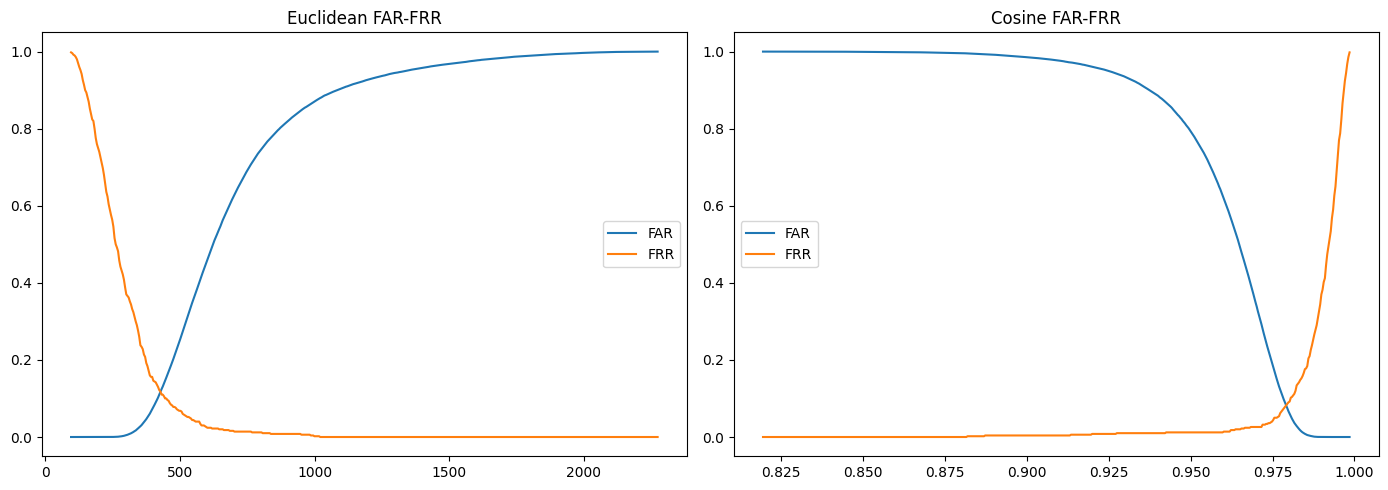

In [ ]:
# Euclidean

eu_thresholds = np.linspace(
    min(eu_genuine.min(), eu_imposter.min()),
    max(eu_genuine.max(), eu_imposter.max()),
    500
)

eu_far = []
eu_frr = []

for t in eu_thresholds:

    far = np.mean(eu_imposter <= t)

    frr = np.mean(eu_genuine > t)

    eu_far.append(far)
    eu_frr.append(frr)

eu_far = np.array(eu_far)
eu_frr = np.array(eu_frr)

# Cosine

cos_thresholds = np.linspace(
    min(cos_imposter.min(), cos_genuine.min()),
    max(cos_imposter.max(), cos_genuine.max()),
    500
)

cos_far = []
cos_frr = []

for t in cos_thresholds:

    far = np.mean(cos_imposter >= t)

    frr = np.mean(cos_genuine < t)

    cos_far.append(far)
    cos_frr.append(frr)

cos_far = np.array(cos_far)
cos_frr = np.array(cos_frr)

# Plot

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(eu_thresholds, eu_far, label="FAR")
plt.plot(eu_thresholds, eu_frr, label="FRR")
plt.title("Euclidean FAR-FRR")
plt.legend()

plt.subplot(1,2,2)
plt.plot(cos_thresholds, cos_far, label="FAR")
plt.plot(cos_thresholds, cos_frr, label="FRR")
plt.title("Cosine FAR-FRR")
plt.legend()

plt.tight_layout()
plt.show()

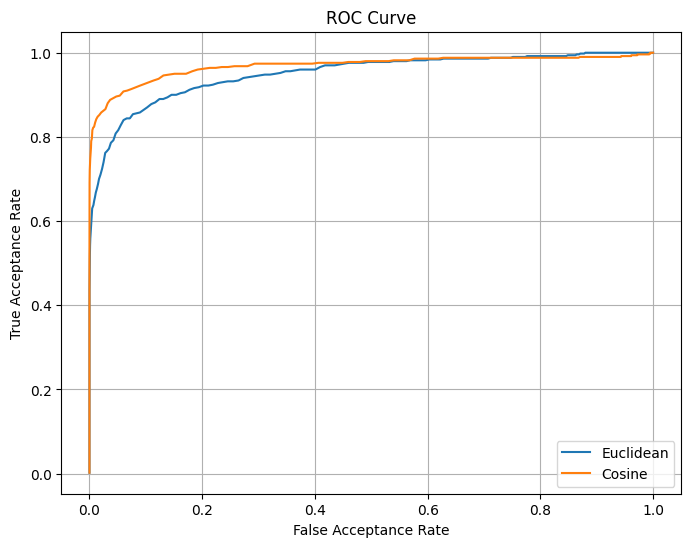


========== FINAL RESULTS ==========

Euclidean Distance
EER = 0.117364
Decidability = 1.758324

Cosine Similarity
EER = 0.082343
Decidability = 1.922647

Best Method:
Cosine Similarity performs better.


In [ ]:
# ROC

eu_tpr = 1 - eu_frr
cos_tpr = 1 - cos_frr

plt.figure(figsize=(8,6))

plt.plot(eu_far,
         eu_tpr,
         label="Euclidean")

plt.plot(cos_far,
         cos_tpr,
         label="Cosine")

plt.xlabel("False Acceptance Rate")
plt.ylabel("True Acceptance Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)

plt.show()

# EER

eu_idx = np.argmin(np.abs(eu_far - eu_frr))
eu_eer = (eu_far[eu_idx] + eu_frr[eu_idx]) / 2

cos_idx = np.argmin(np.abs(cos_far - cos_frr))
cos_eer = (cos_far[cos_idx] + cos_frr[cos_idx]) / 2

# Decidability

eu_decidability = abs(
    np.mean(eu_genuine) -
    np.mean(eu_imposter)
) / np.sqrt(
    (np.var(eu_genuine) +
     np.var(eu_imposter)) / 2
)

cos_decidability = abs(
    np.mean(cos_genuine) -
    np.mean(cos_imposter)
) / np.sqrt(
    (np.var(cos_genuine) +
     np.var(cos_imposter)) / 2
)

print("\n========== FINAL RESULTS ==========\n")

print("Euclidean Distance")
print("EER =", round(eu_eer, 6))
print("Decidability =", round(eu_decidability, 6))

print()

print("Cosine Similarity")
print("EER =", round(cos_eer, 6))
print("Decidability =", round(cos_decidability, 6))

print("\nBest Method:")

if cos_eer < eu_eer and cos_decidability > eu_decidability:
    print("Cosine Similarity performs better.")
elif eu_eer < cos_eer and eu_decidability > cos_decidability:
    print("Euclidean Distance performs better.")
else:
    print("Compare EER and Decidability values manually.")

In [ ]:
print("========== FINAL RESULTS ==========")

print("\nEuclidean Distance")
print("EER =", eu_eer)
print("Decidability Index =", eu_decidability)

print("\nCosine Similarity")
print("EER =", cos_eer)
print("Decidability Index =", cos_decidability)

========== FINAL RESULTS ==========

Euclidean Distance
EER = 0.11736363636363636
Decidability Index = 1.7583239600321199

Cosine Similarity
EER = 0.08234343434343434
Decidability Index = 1.9226465962513535
